# Notebook 05: Đánh giá Thực nghiệm Định tính & Định lượng trên 90 Ảnh UAV (Mục 4 Báo cáo)
**Phụ trách:** Thành viên 4

Chạy đánh giá toàn diện trên:
- **Bảng 1:** 30 cặp ảnh đối chứng có tham chiếu (`data/synthetic_gt/` vs `data/synthetic_degraded/`) với các chỉ số **PSNR (dB)** $\uparrow$, **SSIM** $\uparrow$, **Sai số màu $\Delta E_{ab}$** $\downarrow$, **Pink Cast (%)** $\downarrow$.
- **Bảng 2:** 60 ảnh bay UAV thực nghiệm (`data/real_uav/`) với các chỉ số **Shannon Entropy (bits)** $\uparrow$, **Laplacian Variance** $\uparrow$, **Pink Cast (%)** $\downarrow$, **Runtime (ms/frame)** $\downarrow$ và **FPS** $\uparrow$.

In [1]:
import pandas as pd
ROOT = "/home/ngtukien/Projects/XLA"
df_t1 = pd.read_csv(f"{ROOT}/results/tables/table1_synthetic_metrics.csv")
print("=== BẢNG 1: KẾT QUẢ ĐỊNH LƯỢNG TRÊN TẬP ĐỐI CHỨNG CÓ THAM CHIẾU (30 CẶP ẢNH) ===")
df_t1

=== BẢNG 1: KẾT QUẢ ĐỊNH LƯỢNG TRÊN TẬP ĐỐI CHỨNG CÓ THAM CHIẾU (30 CẶP ẢNH) ===


Method,Resolution,PSNR (dB),SSIM,DeltaE_ab,Entropy (bits),Laplacian_Var,Pink_Cast (%)
1. Ảnh suy giảm (ESP32-CAM 640x480),800x600,20.35,0.7015,24.74,6.648,142.2,8.52
2. Đối chứng 1: Global HE (RGB),800x600,12.53,0.4155,59.38,7.888,1760.8,8.98
3. Đối chứng 2: Global HE (LAB),800x600,13.09,0.4214,52.17,7.542,1782.3,8.69
4. Giai đoạn 1: Wavelet+NLM + Khử hồng,800x600,20.89,0.7639,22.98,6.526,52.4,2.61
5. Giai đoạn 1+2: + Haze-Pivot & CLAHE,800x600,27.66,0.8295,9.89,6.884,109.8,5.68
6. Pipeline Đề xuất (3 Giai đoạn - VGA),800x600,27.42,0.8180,10.06,6.917,186.9,5.61
7. Pipeline Đề xuất + ESPCN HD 720p (960x720),960x720,27.40,0.8051,10.09,6.917,134.1,5.67
8. Pipeline Đề xuất + ESPCN Full HD 1080p (1440x1080),1440x1080,27.33,0.7881,10.16,6.910,54.2,5.63


In [2]:
df_t2 = pd.read_csv(f"{ROOT}/results/tables/table2_real_uav_metrics.csv")
print("=== BẢNG 2: KẾT QUẢ ĐỊNH LƯỢNG TRÊN TẬP 60 ẢNH BAY UAV THỰC NGHIỆM ===")
df_t2

=== BẢNG 2: KẾT QUẢ ĐỊNH LƯỢNG TRÊN TẬP 60 ẢNH BAY UAV THỰC NGHIỆM ===


Method,Resolution,Entropy (bits),Laplacian_Var,Pink_Cast (%),Runtime (ms),FPS
1. Ảnh gốc ESP32-CAM (640x480),800x600,6.364,121.1,17.45,0.00,0.0
2. Đối chứng 1: Global HE (RGB),800x600,7.461,1108.4,12.28,0.85,1231.3
3. Đối chứng 2: Global HE (LAB),800x600,7.206,1303.7,17.27,1.84,550.9
4. Giai đoạn 1: Wavelet+NLM + Khử hồng,800x600,6.320,59.4,2.55,157.51,6.4
5. Giai đoạn 1+2: + Haze-Pivot & CLAHE,800x600,6.817,120.0,7.11,166.01,6.1
6. Pipeline Đề xuất (VGA 640x480),800x600,6.850,226.5,7.03,436.59,2.3
7. Pipeline Đề xuất + ESPCN HD 720p (960x720),960x720,6.860,153.3,7.05,476.24,2.1
8. Pipeline Đề xuất + ESPCN Full HD 1080p (1440x1080),1440x1080,6.853,56.8,7.01,614.68,1.6


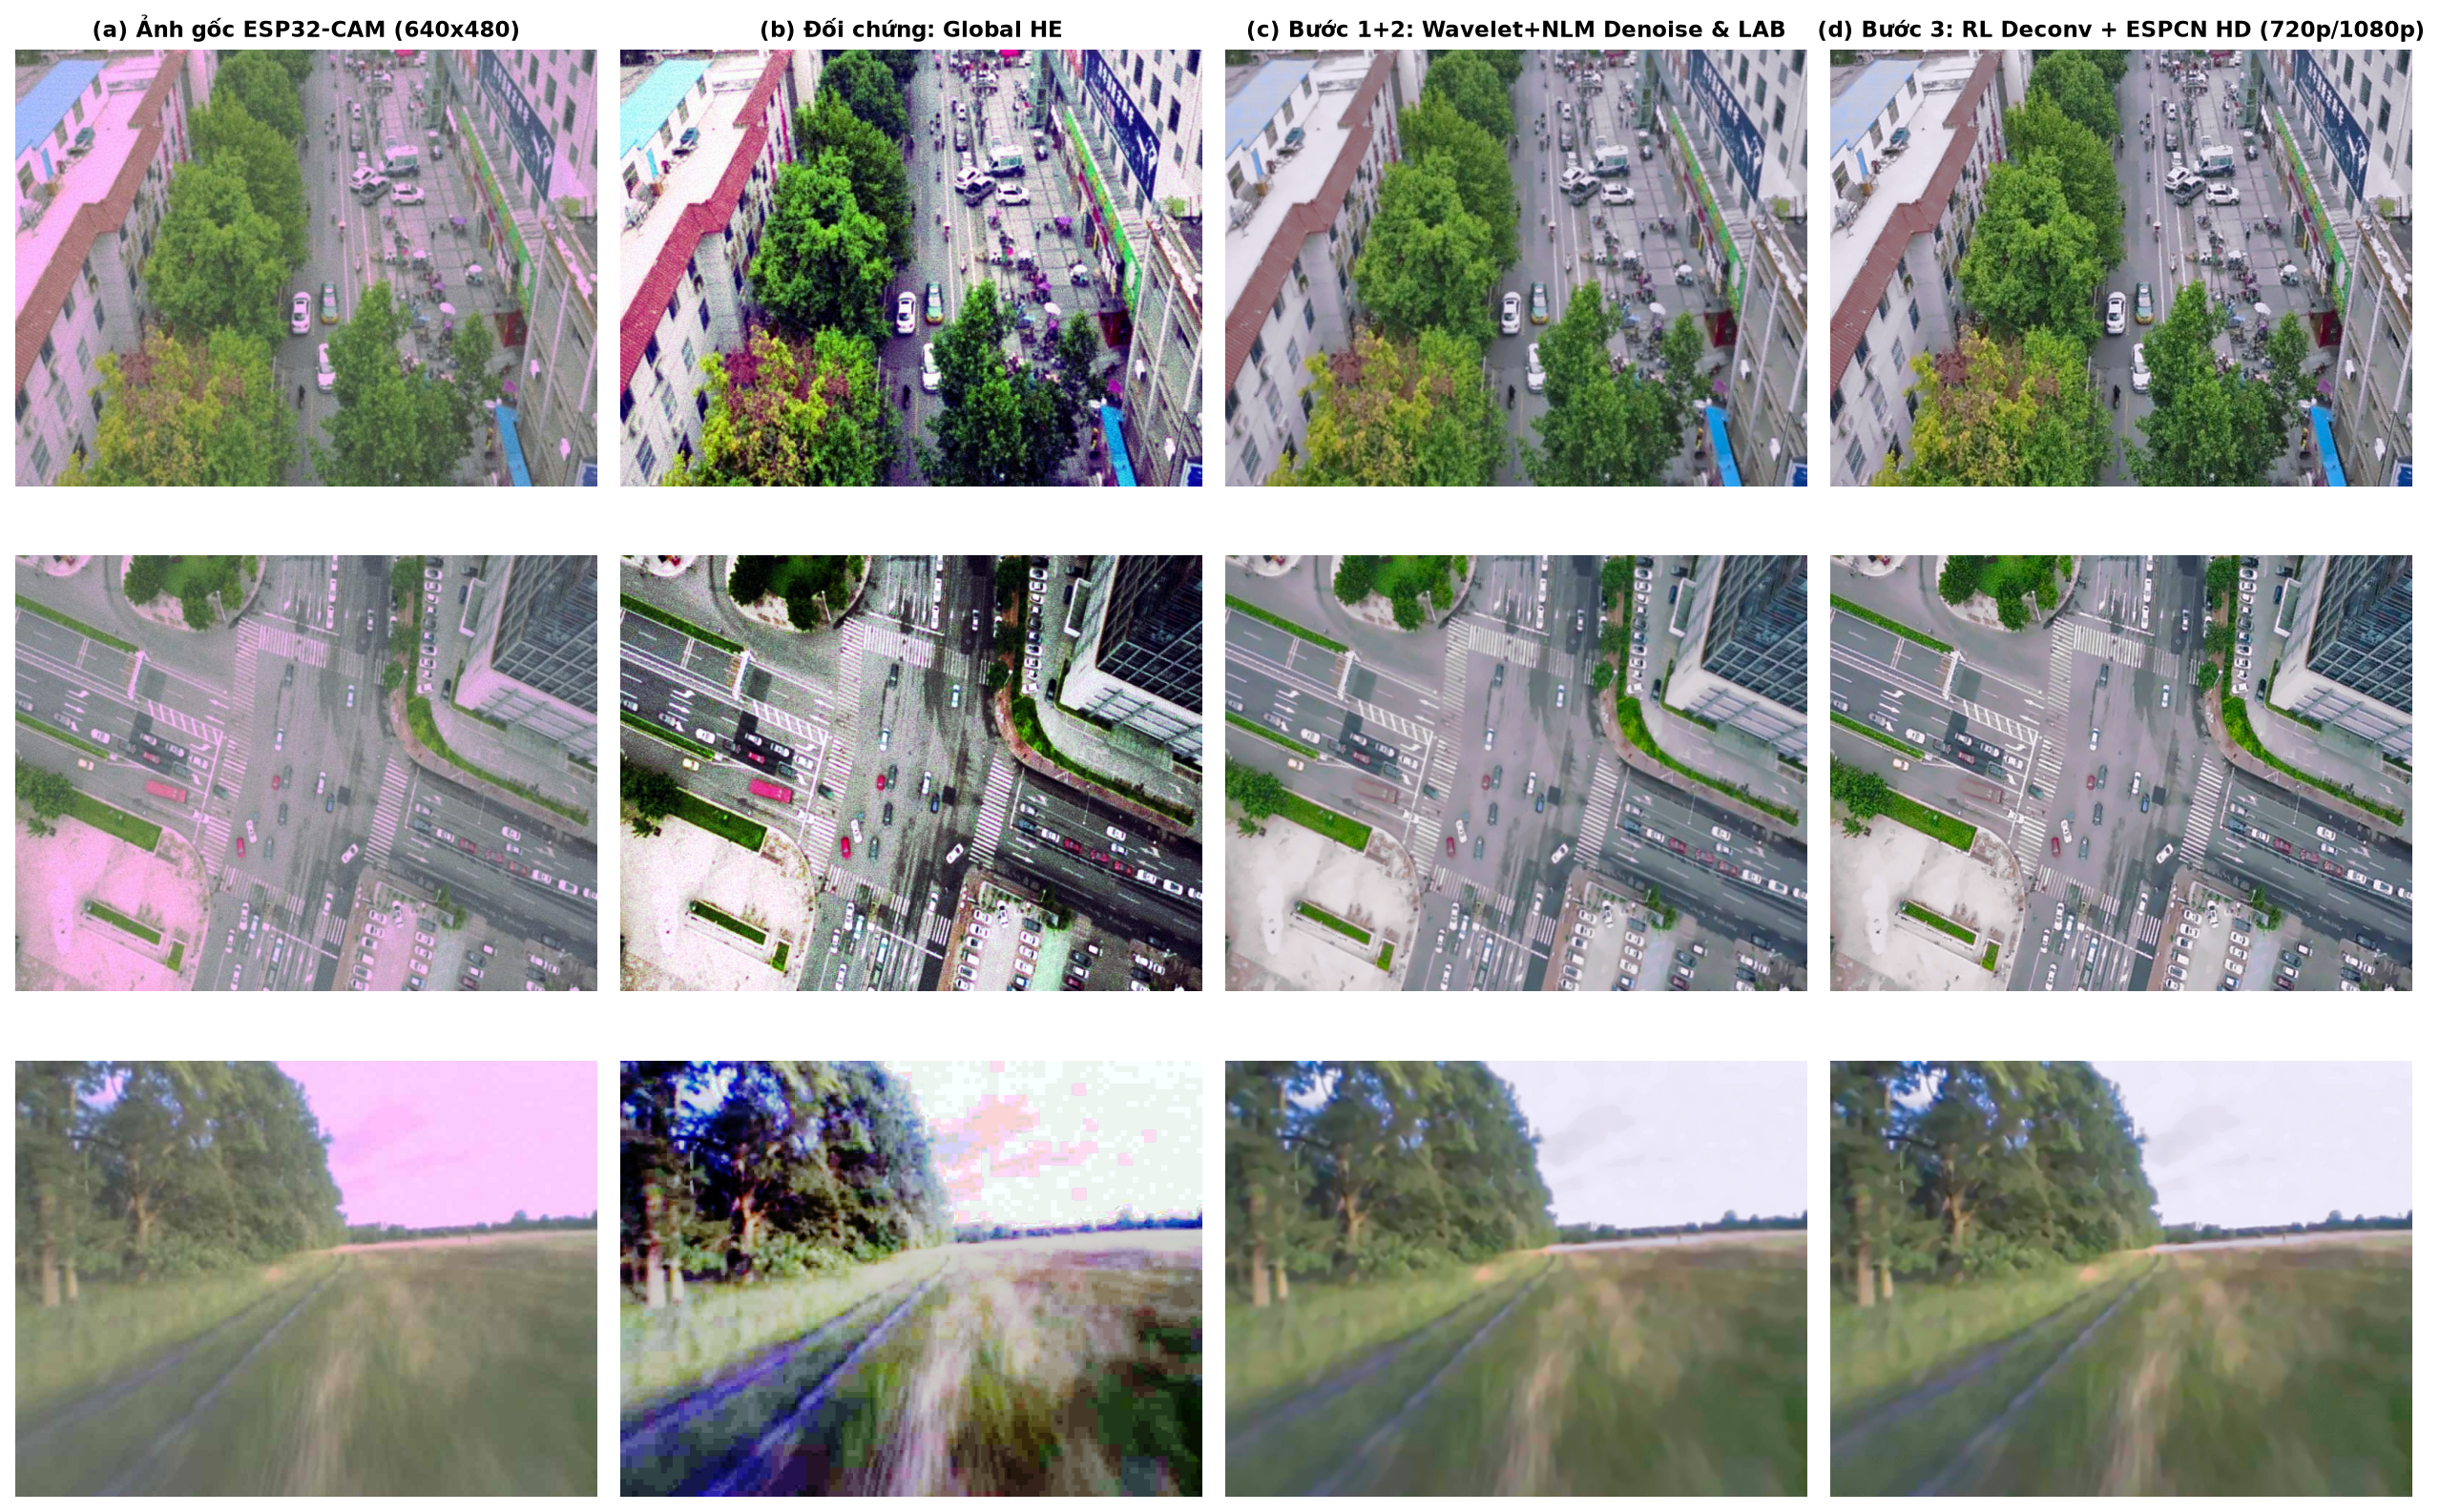

In [3]:
# Hiển thị lưới so sánh trực quan 4 cột (Mục 4.1)